# Лабораторная работа №4
Вычисления с использованием языка ассемблера.

Монгуш Темир Мергенович · ИУ5-35Б · Вариант 11

Задачи 8, 9 и 14. Ввод параметров через системный вызов `read`.

[Условие](https://github.com/junaart/System_programming/blob/master/Lab_4/Lab_4.ipynb)

Ячейки выполняются сверху вниз. Проверено в Linux x86-64 с FASM.

## Подготовка

In [1]:
%%bash
set -e
if ! dpkg -s fasm binutils gcc file >/dev/null 2>&1; then
    SUDO=()
    if [ "$(id -u)" -ne 0 ]; then SUDO=(sudo); fi
    "${SUDO[@]}" apt-get update -qq
    "${SUDO[@]}" env DEBIAN_FRONTEND=noninteractive apt-get install -y -qq fasm binutils gcc file
fi
mkdir -p Lab_4
uname -sm
fasm | head -n 1
gcc --version | head -n 1

Linux x86_64
flat assembler  version 1.73.32
gcc (Debian 14.2.0-19) 14.2.0


## Вариант

In [2]:
import random as rd
Variant = 11
rd.seed(Variant)
tasks = [i+1 for i in rd.sample(range(14),3)]
print('Номера задач:',tasks)
assert tasks == [8,9,14]

Номера задач: [8, 9, 14]


## Процедуры ввода и вывода

In [3]:
%%writefile Lab_4/common.inc
; Linux x86-64. Вспомогательные процедуры по образцу func.asm из лекций.
; rbx, rbp, r12-r15 сохраняются; остальные регистры могут изменяться.
; parse_uint: rsi -> строка, rax <- число; строгая проверка uint64.
parse_uint:
    xor eax, eax
    mov r8d, 10
    cmp byte [rsi], 0
    je error
.loop:
    movzx r9d, byte [rsi]
    test r9b, r9b
    jz .done
    sub r9d, '0'
    cmp r9d, 9
    ja error
    mul r8
    test rdx, rdx
    jnz error
    add rax, r9
    jc error
    inc rsi
    jmp .loop
.done:
    ret

; parse_int: rsi -> строка, rax <- int64.
parse_int:
    xor r10d, r10d
    cmp byte [rsi], '-'
    jne .positive
    inc rsi
    inc r10d
    jmp .convert
.positive:
    cmp byte [rsi], '+'
    jne .convert
    inc rsi
.convert:
    call parse_uint
    mov r9, 7FFFFFFFFFFFFFFFh
    add r9, r10
    cmp rax, r9
    ja error
    test r10d, r10d
    jz .done
    neg rax
.done:
    ret

; read_uint: ввод одной строки через read(0,...), результат в rax.
read_uint:
    xor r10d, r10d
.loop:
    xor eax, eax
    xor edi, edi
    lea rsi, [input_buffer+r10]
    mov edx, 1
    syscall
    test rax, rax
    js error
    jz .done
    cmp byte [rsi], 10
    je .done
    inc r10
    cmp r10, 31
    jae error
    jmp .loop
.done:
    mov byte [input_buffer+r10], 0
    mov rsi, input_buffer
    jmp parse_uint

; print_int: вывести int64 из rax и перевод строки через write.
print_int:
    xor r10d, r10d
    test rax, rax
    jns .convert
    inc r10d
    neg rax
.convert:
    mov r8d, 10
    mov rsi, number_buffer+31
    mov byte [rsi], 10
    mov edx, 1
.loop:
    push rdx
    xor edx, edx
    div r8
    add dl, '0'
    dec rsi
    mov [rsi], dl
    pop rdx
    inc rdx
    test rax, rax
    jnz .loop
    test r10d, r10d
    jz .write
    dec rsi
    mov byte [rsi], '-'
    inc rdx
.write:
    mov edi, 1
    mov eax, 1
    syscall
    ret

exit:
    mov eax, 60
    xor edi, edi
    syscall
error:
    mov eax, 1
    mov edi, 2
    mov rsi, error_message
    mov edx, error_length
    syscall
    mov eax, 60
    mov edi, 1
    syscall

section '.data' writable
error_message db 'Invalid input or I/O error',10
error_length = $-error_message
section '.bss' writable
input_buffer rb 32
number_buffer rb 32

Writing Lab_4/common.inc


## Задача 8. Чередование цифр числа через нуль: 123 → 102030. Диапазон n: 0…999999999.

In [4]:
%%writefile Lab_4/task8.asm
; Между цифрами и после последней цифры ставится 0. n <= 999999999.
format ELF64
public _start
section '.text' executable
_start:
    call read_uint
    cmp rax, 999999999
    ja error
    mov ebx, 10
    mov r12d, 10                     ; разряд цифры в результате
    xor r13d, r13d
.digit:
    xor edx, edx
    div rbx
    imul rdx, r12
    add r13, rdx
    imul r12, r12, 100
    test rax, rax
    jnz .digit
    mov rax, r13
    call print_int
    jmp exit
include 'common.inc'

Writing Lab_4/task8.asm


In [5]:
%%writefile Lab_4/task8.c
#include <stdio.h>
#include <stdlib.h>
#include <stdint.h>
#include <inttypes.h>
#include <errno.h>
int main(void) {
    char s[64], *end;
    if (!fgets(s, sizeof s, stdin) || s[0] < '0' || s[0] > '9') return 1;
    errno = 0;
    uint64_t n = strtoull(s, &end, 10);
    if (errno || (*end && *end != '\n') || n > 999999999ULL) return 1;
    uint64_t result = 0, place = 10;
    do { result += n % 10 * place; n /= 10; place *= 100; } while (n);
    printf("%" PRIu64 "\n", result);
    return 0;
}

Writing Lab_4/task8.c


In [6]:
%%bash
set -e
cd Lab_4
fasm task8.asm task8.o >/dev/null
ld task8.o -o task8
gcc -Wall -Wextra -O0 task8.c -o task8_c

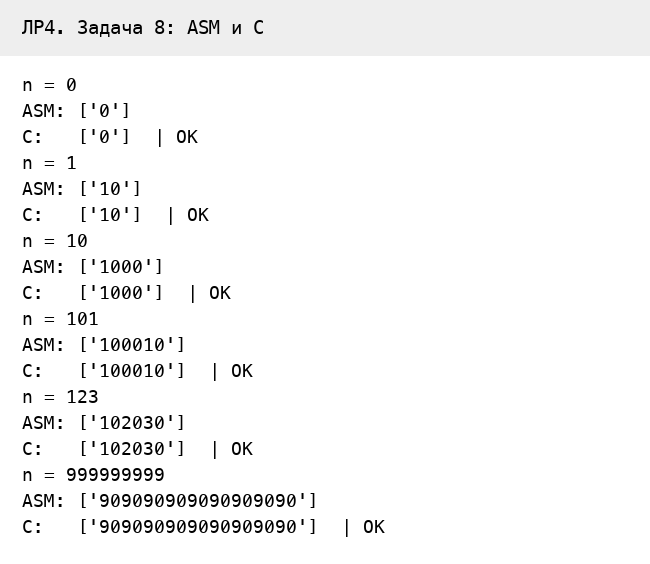

In [7]:
from pathlib import Path
import subprocess
p = Path('Lab_4').resolve()
for n in [0, 1, 10, 101, 123, 999999999]:
    asm = subprocess.check_output([str(p/'task8')],input=str(n)+'\n',text=True)
    cpp = subprocess.check_output([str(p/'task8_c')],input=str(n)+'\n',text=True)
    expected = str(int("".join(d+"0" for d in str(n)))) + "\n"
    assert asm == cpp == expected
    print('n =',n)
    print('ASM:',asm.split())
    print('C:  ',cpp.split(),' | OK')

## Задача 9. Сумма 1+2−3−4+5+6−7−8+…±n. Диапазон n: 0…1000000000.

In [8]:
%%writefile Lab_4/task9.asm
; Сумма 1+2-3-4+5+6-7-8+...; 0 <= n <= 1000000000.
format ELF64
public _start
section '.text' executable
_start:
    call read_uint
    cmp rax, 1000000000
    ja error
    mov r12, rax
    xor r13d, r13d                  ; сумма
    mov ebx, 1
.loop:
    cmp rbx, r12
    ja .done
    mov rax, rbx
    dec rax
    test rax, 2                     ; знаки +,+,-,-
    jz .plus
    sub r13, rbx
    jmp .next
.plus:
    add r13, rbx
.next:
    inc rbx
    jmp .loop
.done:
    mov rax, r13
    call print_int
    jmp exit
include 'common.inc'

Writing Lab_4/task9.asm


In [9]:
%%writefile Lab_4/task9.c
#include <stdio.h>
#include <stdlib.h>
#include <stdint.h>
#include <inttypes.h>
#include <errno.h>
int main(void) {
    char s[64], *end;
    if (!fgets(s, sizeof s, stdin) || s[0] < '0' || s[0] > '9') return 1;
    errno = 0;
    uint64_t n = strtoull(s, &end, 10);
    if (errno || (*end && *end != '\n') || n > 1000000000ULL) return 1;
    int64_t sum = 0;
    for (uint64_t k = 1; k <= n; ++k)
        sum += ((k-1) & 2) ? -(int64_t)k : (int64_t)k;
    printf("%" PRId64 "\n", sum);
    return 0;
}

Writing Lab_4/task9.c


In [10]:
%%bash
set -e
cd Lab_4
fasm task9.asm task9.o >/dev/null
ld task9.o -o task9
gcc -Wall -Wextra -O0 task9.c -o task9_c

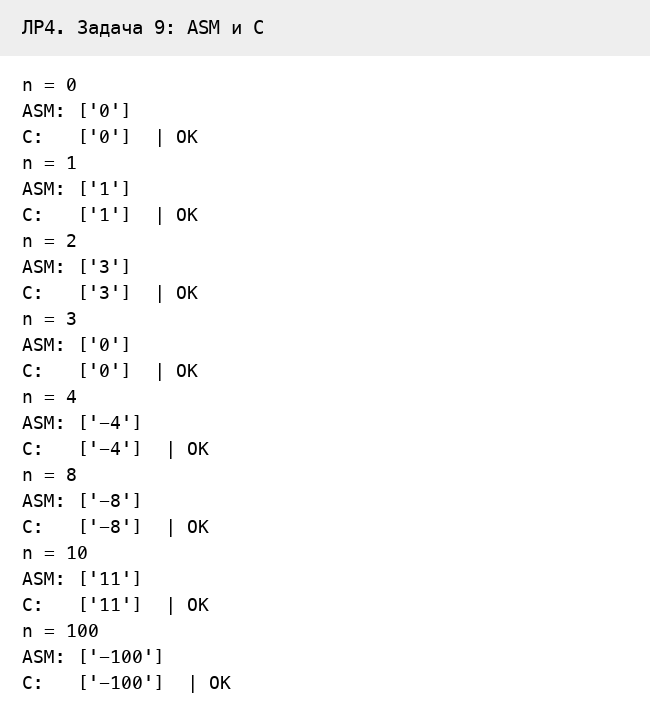

In [11]:
from pathlib import Path
import subprocess
p = Path('Lab_4').resolve()
for n in [0, 1, 2, 3, 4, 8, 10, 100]:
    asm = subprocess.check_output([str(p/'task9')],input=str(n)+'\n',text=True)
    cpp = subprocess.check_output([str(p/'task9_c')],input=str(n)+'\n',text=True)
    expected = str(sum(k if (k-1)%4<2 else -k for k in range(1,n+1))) + "\n"
    assert asm == cpp == expected
    print('n =',n)
    print('ASM:',asm.split())
    print('C:  ',cpp.split(),' | OK')

## Задача 14. Числа от 1 до n, совпадающие с последними цифрами своего квадрата. Диапазон n: 0…1000000.

In [12]:
%%writefile Lab_4/task14.asm
; Автоморфные числа: k*k mod 10^(число цифр k) = k. n <= 1000000.
format ELF64
public _start
section '.text' executable
_start:
    call read_uint
    cmp rax, 1000000
    ja error
    mov r12, rax
    mov ebx, 1
    mov r13d, 10
.loop:
    cmp rbx, r12
    ja exit
    cmp rbx, r13
    jb .square
    imul r13, r13, 10
.square:
    mov rax, rbx
    imul rax, rbx
    xor edx, edx
    div r13
    cmp rdx, rbx
    jne .next
    mov rax, rbx
    call print_int
.next:
    inc rbx
    jmp .loop
include 'common.inc'

Writing Lab_4/task14.asm


In [13]:
%%writefile Lab_4/task14.c
#include <stdio.h>
#include <stdlib.h>
#include <stdint.h>
#include <inttypes.h>
#include <errno.h>
int main(void) {
    char s[64], *end;
    if (!fgets(s, sizeof s, stdin) || s[0] < '0' || s[0] > '9') return 1;
    errno = 0;
    uint64_t n = strtoull(s, &end, 10);
    if (errno || (*end && *end != '\n') || n > 1000000ULL) return 1;
    uint64_t power = 10;
    for (uint64_t k = 1; k <= n; ++k) {
        if (k == power) power *= 10;
        if (k*k % power == k) printf("%" PRIu64 "\n", k);
    }
    return 0;
}

Writing Lab_4/task14.c


In [14]:
%%bash
set -e
cd Lab_4
fasm task14.asm task14.o >/dev/null
ld task14.o -o task14
gcc -Wall -Wextra -O0 task14.c -o task14_c

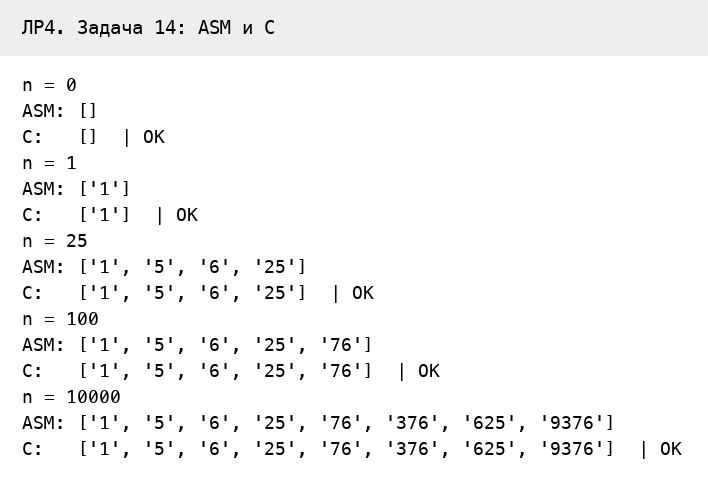

In [15]:
from pathlib import Path
import subprocess
p = Path('Lab_4').resolve()
for n in [0, 1, 25, 100, 10000]:
    asm = subprocess.check_output([str(p/'task14')],input=str(n)+'\n',text=True)
    cpp = subprocess.check_output([str(p/'task14_c')],input=str(n)+'\n',text=True)
    expected = "".join(str(k)+"\n" for k in range(1,n+1) if str(k*k).endswith(str(k)))
    assert asm == cpp == expected
    print('n =',n)
    print('ASM:',asm.split())
    print('C:  ',cpp.split(),' | OK')